In [1]:
# Run this first in a fresh Colab runtime. Exact versions, no credentials needed.
import os, sys, subprocess, importlib.metadata
os.environ['OPENBLAS_NUM_THREADS'] = '1'
os.environ['OMP_NUM_THREADS'] = '1'
os.environ['MKL_NUM_THREADS'] = '1'
PINS = {'rdkit':'2025.9.6', 'pandas':'2.2.3', 'numpy':'2.3.5',
        'scikit-learn':'1.8.0', 'statsmodels':'0.14.6', 'requests':'2.32.5',
        'matplotlib':'3.10.8', 'scipy':'1.17.0'}
def installed(package):
    try: return importlib.metadata.version(package)
    except importlib.metadata.PackageNotFoundError: return None
if any(installed(k) != v for k,v in PINS.items()):
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q',
                           *[f'{k}=={v}' for k,v in PINS.items()]])
print('Python', sys.version.split()[0])
for package, expected in PINS.items():
    actual = installed(package)
    assert actual == expected, (package, actual, expected)
    print(f'{package}=={actual}')


Python 3.12.14
rdkit==2025.9.6
pandas==2.2.3
numpy==2.3.5
scikit-learn==1.8.0
statsmodels==0.14.6
requests==2.32.5
matplotlib==3.10.8
scipy==1.17.0


# Reproducible Hansch-style QSAR: human DRD2

**One target:** dopamine D2 receptor, **DRD2 / CHEMBL217 / UniProt P14416**.
**One assay type:** binding (**B**). **One activity type:** **Ki**. The sole response is
**pActivity = median pChEMBL = −log10(Ki in mol/L)**; the reported nM values are eligibility
metadata and are never used as a second response.

**Requested scaffold split: 80/20.** In the frozen 250-compound dataset the seeded
whole-scaffold allocation is **195 training / 55 test (78/22)**. Group integrity takes
precedence over splitting a scaffold to obtain an exact count; the allocation is fixed
before fitting and is not tuned after observing the outcomes.

Run all cells in order in a fresh Colab runtime. By default the notebook downloads a
SHA-256-verified frozen archive of ChEMBL REST JSON from an immutable repository commit,
unpacks it using Python `zipfile`, and then runs without network access. It writes all
results to `hansch_drd2/` and repeats the complete analysis to require byte-identical
`model.json`. Preserve `hansch_drd2/cache/` with the results: live ChEMBL can change.
A cache miss in cache-only mode fails loudly. To intentionally collect a new live dataset,
set `QSAR_LIVE_REFRESH=1` before the configuration cell; that uses a separate cache.
The final export is `qsar_drd2.json`, copied unchanged to the existing site's data folder.

The scaffold holdout, 5-fold scaffold-group CV, and leave-one-out validation each perform
feature selection **using only their training rows**. The full-data model is a separate,
descriptive fit. All coefficient tests are exploratory post-selection diagnostics.


In [2]:
import csv, hashlib, io, json, math, time, warnings, zipfile
from datetime import datetime, timezone
from pathlib import Path
from urllib.parse import urlencode, urlsplit, urlunsplit, parse_qsl
import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.model_selection import GroupKFold
from sklearn.metrics import r2_score, mean_squared_error
from rdkit import Chem, RDLogger
from rdkit.Chem import Crippen, Descriptors, Lipinski, QED, rdMolDescriptors, SaltRemover
from rdkit.Chem.MolStandardize import rdMolStandardize
from rdkit.Chem.Scaffolds import MurckoScaffold
from IPython.display import display, Markdown, Image
RDLogger.DisableLog('rdApp.*')  # Per-structure failures are recorded in dropped.csv.
SEED = 42  # The only random seed; used by every shuffle and split.
OUT = Path(os.environ.get('QSAR_OUTPUT_DIR', 'hansch_drd2'))
LIVE_REFRESH = os.environ.get('QSAR_LIVE_REFRESH', '0') == '1'
CACHE = Path(os.environ.get('QSAR_CACHE_DIR', str(OUT / ('live_cache' if LIVE_REFRESH else 'cache'))))
CACHE_ONLY = os.environ.get('QSAR_CACHE_ONLY', '0') == '1'
OUT.mkdir(parents=True, exist_ok=True)
CACHE.mkdir(parents=True, exist_ok=True)
(OUT / 'figures').mkdir(exist_ok=True)
BASE = 'https://www.ebi.ac.uk/chembl/api/data/'
TARGET_ID, GENE, STANDARD_TYPE, ASSAY_TYPE = 'CHEMBL217', 'DRD2', 'Ki', 'B'
SITE_COMMIT = '71ebf5d38a24b79030bc0a68ccf6a236c11a61da'
SITE_DRUGS_URL = ('https://raw.githubusercontent.com/DhruvMenon2003/'
                  f'drug-hansch-space/{SITE_COMMIT}/data/drugs.json')
SNAPSHOT_COMMIT = 'b6d42018a25b35410548e822fc4d2b31b9bd2bc7'
SNAPSHOT_SHA256 = '184a23c8f6bfc8d16e33fb7e18da18e22b317af5283a29f0e43f0650bb151473'
SNAPSHOT_URL = ('https://raw.githubusercontent.com/DhruvMenon2003/'
                f'drug-toxicity-qsar-prediction/{SNAPSHOT_COMMIT}/curation/hansch_drd2_cache.zip')
_SNAPSHOT_READY = False
SESSION = requests.Session()
SESSION.headers.update({'User-Agent':'hansch-qsar-reproducibility/1', 'Accept':'application/json'})

def masked_url(url):
    parts = urlsplit(url)
    query = [(k, 'REDACTED' if k.lower() in {'api_key','apikey','key','token','access_token'} else v)
             for k,v in parse_qsl(parts.query, keep_blank_values=True)]
    return urlunsplit((parts.scheme, parts.netloc, parts.path, urlencode(query), parts.fragment))

def log_request(url, status, attempt, cached, source_utc=''):
    path = OUT / 'provenance.csv'
    fresh = not path.exists()
    with path.open('a', newline='', encoding='utf-8') as f:
        w = csv.writer(f)
        if fresh: w.writerow(['url','status','utc','attempt','cached','source_utc'])
        w.writerow([masked_url(url), status, datetime.now(timezone.utc).isoformat(),
                    attempt, cached, source_utc])

def get_bytes(endpoint, params=None):
    """The only HTTP helper: immutable body cache, integrity check, every attempt logged."""
    url = endpoint if endpoint.startswith('https://') else BASE + endpoint
    if params: url += '?' + urlencode(sorted(params.items()))
    key = hashlib.sha256(url.encode()).hexdigest()
    body_path, meta_path = CACHE / f'{key}.json', CACHE / f'{key}.meta.json'
    if body_path.exists() and meta_path.exists():
        payload = body_path.read_bytes()
        meta = json.loads(meta_path.read_text())
        if hashlib.sha256(payload).hexdigest() != meta['sha256']:
            raise RuntimeError(f'Cache integrity failure: {key}')
        log_request(url, meta['status'], 0, True, meta['utc'])
        return payload
    if CACHE_ONLY:
        raise RuntimeError(f'Cache-only run missing {masked_url(url)}')
    for attempt in range(1, 5):
        try:
            response = SESSION.get(url, timeout=90)
        except requests.RequestException:
            log_request(url, 0, attempt, False)
            if attempt == 4: raise RuntimeError(f'HTTP request failed: {masked_url(url)}') from None
            time.sleep(2 ** (attempt - 1))
            continue
        log_request(url, response.status_code, attempt, False)
        if response.status_code in {429, 500, 502, 503, 504} and attempt < 4:
            time.sleep(2 ** (attempt - 1))
            continue
        if not response.ok:
            raise RuntimeError(f'HTTP {response.status_code}: {masked_url(url)}')
        payload = response.content
        body_path.write_bytes(payload)
        meta_path.write_text(json.dumps({'url':masked_url(url), 'status':response.status_code,
            'utc':datetime.now(timezone.utc).isoformat(),
            'sha256':hashlib.sha256(payload).hexdigest()}, sort_keys=True))
        return payload
    raise RuntimeError(f'HTTP retries exhausted: {masked_url(url)}')

def get_json(endpoint, params=None):
    return json.loads(get_bytes(endpoint, params))

def ensure_snapshot():
    """Bootstrap the one frozen archive, using the same HTTP helper as API requests."""
    global CACHE_ONLY, _SNAPSHOT_READY
    if LIVE_REFRESH or _SNAPSHOT_READY: return
    explicit = os.environ.get('QSAR_SNAPSHOT_ARCHIVE')
    paths = ([Path(explicit)] if explicit else []) + [Path('hansch_drd2_cache.zip'),
             Path('curation/hansch_drd2_cache.zip'), Path('pipeline/curation/hansch_drd2_cache.zip')]
    local = next((p for p in paths if p.exists()), None)
    payload = local.read_bytes() if local else get_bytes(SNAPSHOT_URL)
    if hashlib.sha256(payload).hexdigest() != SNAPSHOT_SHA256:
        raise RuntimeError('Frozen cache archive SHA-256 mismatch; refusing to run.')
    with zipfile.ZipFile(io.BytesIO(payload)) as archive:
        manifest = json.loads(archive.read('manifest.json'))
        # Explicit allowlist prevents paths outside CACHE from being extracted.
        for filename, expected in sorted(manifest.items()):
            if Path(filename).name != filename or not filename.endswith('.json'):
                raise RuntimeError('Unexpected path in cache manifest.')
            body = archive.read('cache/' + filename)
            meta_name = filename.removesuffix('.json') + '.meta.json'
            meta_bytes = archive.read('cache/' + meta_name)
            meta = json.loads(meta_bytes)
            if hashlib.sha256(body).hexdigest() != expected or meta['sha256'] != expected:
                raise RuntimeError('Frozen response integrity failure.')
            (CACHE / filename).write_bytes(body)
            (CACHE / meta_name).write_bytes(meta_bytes)
        source = archive.read('source_provenance.csv')
        (OUT / 'source_provenance.csv').write_bytes(source)
    marker = OUT / 'snapshot_provenance_imported.json'
    if not marker.exists() or json.loads(marker.read_text()).get('sha256') != SNAPSHOT_SHA256:
        destination = OUT / 'provenance.csv'
        fresh = not destination.exists()
        with destination.open('a', newline='', encoding='utf-8') as f:
            writer = csv.writer(f)
            if fresh: writer.writerow(['url','status','utc','attempt','cached','source_utc'])
            for row in csv.DictReader(io.StringIO(source.decode())):
                writer.writerow([masked_url(row['url']), row['status'], row['utc'], row['attempt'], False, row['utc']])
        write_json(marker, {'sha256':SNAPSHOT_SHA256})
    CACHE_ONLY = True
    _SNAPSHOT_READY = True
    print(f'Frozen snapshot verified: {len(manifest)} responses; all analysis requests are cache-only.')

def fetch_all(endpoint, field, params):
    first = get_json(endpoint, {**params, 'limit':1000, 'offset':0})
    count = first['page_meta']['total_count']
    rows = first[field]
    for offset in range(1000, count, 1000):
        rows.extend(get_json(endpoint, {**params, 'limit':1000, 'offset':offset})[field])
    if len(rows) != count:
        raise RuntimeError('API pagination changed mid-download; use one complete snapshot.')
    return rows

def write_json(path, obj, compact=False):
    Path(path).write_text(json.dumps(obj, sort_keys=True, allow_nan=False,
        indent=None if compact else 2, separators=(',', ':') if compact else None) + '\n')

def csv_out(frame, name):
    frame.to_csv(OUT / name, index=False, float_format='%.17g', lineterminator='\n')

def require_size(n, stage):
    if n < 40:
        raise RuntimeError(f'STOP: only {n} compounds survive {stage}; >=40 required. '
                           'Filters have NOT been relaxed. Ask before any relaxation.')


## A1 — select and audit the evidence

The target record must be one human protein. Assay confidence is joined from the assay
endpoint; it is not guessed from activity records. `selection.json` reports sequential
row counts and the first failing reason at each filter. Target organism is human; the
requested confidence ≥8 rule can admit cross-species assay evidence. Its actual assay
organisms are reported, rather than silently adding a different eligibility rule.


In [3]:
def acquire():
    target = get_json(f'target/{TARGET_ID}.json')
    status = get_json('status.json')
    assert target['target_type'] == 'SINGLE PROTEIN'
    assert target['organism'] == 'Homo sapiens'
    components = target['target_components']
    assert len(components) == 1 and components[0]['accession'] == 'P14416'
    total = get_json('activity.json', {'target_chembl_id':TARGET_ID, 'limit':1})['page_meta']['total_count']
    rows = fetch_all('activity.json', 'activities', {'target_chembl_id':TARGET_ID, 'standard_type':STANDARD_TYPE})
    assays = fetch_all('assay.json', 'assays', {'target_chembl_id':TARGET_ID})
    by_assay = {a['assay_chembl_id']:a for a in assays}
    missing = sorted({a['assay_chembl_id'] for a in rows} - set(by_assay))
    if missing: raise RuntimeError(f'Assay metadata missing for {len(missing)} assays.')
    counts = [{'reason':'standard_type != Ki', 'rows_in':total,
               'rows_out':len(rows), 'dropped':total-len(rows)}]
    filters = [
        ('standard_relation != =', lambda a: a.get('standard_relation') == '='),
        ('standard_units != nM', lambda a: a.get('standard_units') == 'nM'),
        ('pchembl_value missing or nonfinite', lambda a: a.get('pchembl_value') is not None and np.isfinite(float(a['pchembl_value']))),
        ('assay confidence_score < 8 or missing', lambda a: (by_assay[a['assay_chembl_id']].get('confidence_score') or 0) >= 8),
        ('data_validity_comment nonnull', lambda a: a.get('data_validity_comment') is None),
        ('potential_duplicate != 0', lambda a: a.get('potential_duplicate') == 0),
        ('assay_type != B', lambda a: a.get('assay_type') == ASSAY_TYPE and by_assay[a['assay_chembl_id']].get('assay_type') == ASSAY_TYPE),
    ]
    for reason, predicate in filters:
        before = len(rows)
        rows = [a for a in rows if predicate(a)]
        counts.append({'reason':reason, 'rows_in':before, 'rows_out':len(rows), 'dropped':before-len(rows)})
    for row in rows:
        assay = by_assay[row['assay_chembl_id']]
        row['assay_confidence_score'] = assay['confidence_score']
        row['assay_organism'] = assay.get('assay_organism')
    columns = ['activity_id','molecule_chembl_id','parent_molecule_chembl_id','canonical_smiles',
        'pchembl_value','document_chembl_id','assay_chembl_id','assay_confidence_score','assay_type',
        'assay_organism','standard_type','standard_relation','standard_units','standard_value',
        'potential_duplicate','data_validity_comment','target_chembl_id','target_organism']
    raw = pd.DataFrame(rows).reindex(columns=columns).sort_values('activity_id').reset_index(drop=True)
    csv_out(raw, 'raw_activities.csv')
    selection = {'target_chembl_id':TARGET_ID, 'target_name':target['pref_name'], 'gene_symbol':GENE,
        'uniprot_accession':components[0]['accession'], 'organism':target['organism'],
        'target_type':target['target_type'], 'standard_type':STANDARD_TYPE, 'assay_type':ASSAY_TYPE,
        'chembl_status':status, 'filter_counts':counts, 'retained_activities':len(raw),
        'retained_molecule_ids':int(raw.molecule_chembl_id.nunique()),
        'retained_smiles':int(raw.canonical_smiles.nunique()), 'missing_assay_ids':missing,
        'assay_confidence_counts':{str(k):int(v) for k,v in raw.assay_confidence_score.value_counts().sort_index().items()},
        'assay_organism_counts':{str(k):int(v) for k,v in raw.assay_organism.fillna('unknown').value_counts().sort_index().items()},
        'assay_organisms':sorted({str(a['assay_organism']) for a in rows})}
    write_json(OUT / 'selection.json', selection)
    require_size(raw.molecule_chembl_id.nunique(), 'activity eligibility')
    return raw, selection


## A2 — one standardized compound, one pActivity

Standardization follows the requested order: parse → SaltRemover → uncharge → remove
standalone solvents → largest fragment → canonical tautomer → canonical isomeric SMILES
and full InChIKey. Solvent identities are explicit below; a single-fragment structure is
not discarded just because it matches a solvent. Deduplication uses the complete InChIKey,
including stereochemistry. Replicate spread is max−min **pChEMBL**, and median aggregation
requires at least two distinct nonempty document IDs. Different measurements in one
publication do not count as independent documents. A spread exactly 1.0 is allowed.


In [4]:
SALT_REMOVER = SaltRemover.SaltRemover()
UNCHARGER = rdMolStandardize.Uncharger()
LARGEST = rdMolStandardize.LargestFragmentChooser()
TAUTOMER = rdMolStandardize.TautomerEnumerator()
SOLVENT_SMILES = ['O','CO','CCO','CC(C)O','CC(=O)C','CS(C)=O','CN(C)C=O',
                 'CC#N','C1CCOC1','ClCCl','ClC(Cl)Cl','CCOC(C)=O','CCOCC']
SOLVENTS = {Chem.MolToSmiles(Chem.MolFromSmiles(s), canonical=True) for s in SOLVENT_SMILES}

def prepare_structure(smiles):
    if not isinstance(smiles, str) or not smiles.strip(): raise ValueError('missing_smiles')
    mol = Chem.MolFromSmiles(smiles)
    if mol is None: raise ValueError('unparseable_smiles')
    mol = SALT_REMOVER.StripMol(mol, dontRemoveEverything=True)
    mol = UNCHARGER.uncharge(mol)
    fragments = Chem.GetMolFrags(mol, asMols=True, sanitizeFrags=True)
    if len(fragments) > 1:
        nonsolvents = [f for f in fragments if Chem.MolToSmiles(f, canonical=True) not in SOLVENTS]
        if nonsolvents:
            mol = nonsolvents[0]
            for f in nonsolvents[1:]: mol = Chem.CombineMols(mol, f)
    mol = LARGEST.choose(mol)
    return mol

def standardize(smiles):
    mol = prepare_structure(smiles)
    mol = TAUTOMER.Canonicalize(mol)
    Chem.SanitizeMol(mol)
    if mol.GetNumAtoms() == 0: raise ValueError('empty_standardized_structure')
    smiles = Chem.MolToSmiles(mol, canonical=True, isomericSmiles=True)
    key = Chem.MolToInchiKey(mol)
    if not key: raise ValueError('missing_inchikey')
    return key, smiles

def curate(raw):
    standard_by_smiles, structure_errors, drops = {}, {}, []
    for smiles in sorted(raw.canonical_smiles.dropna().unique()):
        try: standard_by_smiles[smiles] = standardize(smiles)
        except Exception as exc: structure_errors[smiles] = type(exc).__name__ + ':' + str(exc)
    rows = []
    for r in raw.to_dict('records'):
        result = standard_by_smiles.get(r['canonical_smiles'])
        if result is None:
            drops.append({'inchikey':'', 'molecule_chembl_ids':r['molecule_chembl_id'],
                'activity_ids':str(r['activity_id']), 'reason':'structure_standardization_failed',
                'pchembl_values':str(r['pchembl_value']), 'detail':structure_errors.get(r['canonical_smiles'],'missing_smiles')})
            continue
        r['InChIKey'], r['canonical_smiles'] = result
        r['pActivity'] = float(r['pchembl_value'])
        rows.append(r)
    standardized = pd.DataFrame(rows)
    kept = []
    for key, group in standardized.groupby('InChIKey', sort=True):
        values = sorted(group.pActivity.tolist())
        docs = sorted({str(d) for d in group.document_chembl_id.dropna() if str(d).strip()})
        assays = sorted(set(group.assay_chembl_id.dropna()))
        mol_ids = sorted(set(group.molecule_chembl_id))
        smiles = sorted(set(group.canonical_smiles))[0]
        spread = max(values) - min(values)
        reasons = []
        if spread > 1.0 + 1e-12: reasons.append('replicate_spread_gt_1_log_unit')
        if len(docs) < 2: reasons.append('fewer_than_2_independent_documents')
        if reasons:
            drops.append({'inchikey':key, 'molecule_chembl_ids':';'.join(mol_ids),
                'activity_ids':';'.join(map(str, sorted(group.activity_id))), 'reason':';'.join(reasons),
                'pchembl_values':json.dumps(values), 'detail':f'n_docs={len(docs)};spread={spread:.17g}'})
        else:
            kept.append({'InChIKey':key, 'canonical_smiles':smiles, 'pActivity':float(np.median(values)),
                'n_assays':len(assays), 'n_docs':len(docs), 'n_measurements':len(group),
                'replicate_spread':spread, 'document_chembl_ids':';'.join(docs),
                'molecule_chembl_ids':';'.join(mol_ids), 'pchembl_values':json.dumps(values)})
    data = pd.DataFrame(kept).sort_values('InChIKey').reset_index(drop=True)
    require_size(len(data), 'standardization, replicate spread and independent-document rules')
    return data, drops

DESCRIPTORS = ['MolLogP','MolMR','TPSA','MolWt','HBD','HBA','RotatableBonds',
               'AromaticRings','FractionCSP3','QED','MolLogP_squared']

def make_features(data, drops):
    values, keep = [], []
    for i, row in data.iterrows():
        mol = Chem.MolFromSmiles(row.canonical_smiles)
        mw = float(Descriptors.MolWt(mol))
        if mw > 1000:
            drops.append({'inchikey':row.InChIKey, 'molecule_chembl_ids':row.molecule_chembl_ids,
                'activity_ids':'', 'reason':'MolWt_gt_1000_Da', 'pchembl_values':row.pchembl_values,
                'detail':f'MolWt={mw:.17g}'})
            continue
        logp = float(Crippen.MolLogP(mol))
        feature = [logp, Crippen.MolMR(mol), rdMolDescriptors.CalcTPSA(mol), mw,
                   Lipinski.NumHDonors(mol), Lipinski.NumHAcceptors(mol), Lipinski.NumRotatableBonds(mol),
                   rdMolDescriptors.CalcNumAromaticRings(mol), rdMolDescriptors.CalcFractionCSP3(mol),
                   QED.qed(mol), logp ** 2]
        if not np.isfinite(feature).all(): raise RuntimeError(f'Nonfinite descriptor for {row.InChIKey}')
        keep.append(i); values.append(feature)
    data = data.loc[keep].reset_index(drop=True)
    X = pd.DataFrame(values, columns=DESCRIPTORS)
    features = pd.concat([data[['InChIKey','canonical_smiles','pActivity']], X], axis=1)
    csv_out(data, 'dataset.csv')
    csv_out(features, 'candidate_features.csv')
    csv_out(pd.DataFrame(drops, columns=['inchikey','molecule_chembl_ids','activity_ids','reason','pchembl_values','detail']), 'dropped.csv')
    require_size(len(data), 'the explorer molecular-weight cutoff (MolWt <= 1000 Da)')
    assert data.InChIKey.is_unique and (data.n_docs >= 2).all()
    assert (data.replicate_spread <= 1 + 1e-12).all()
    return data, X


## A3/A4 — descriptors, selection and validation

The 11 candidates are Crippen MolLogP (the Hansch lipophilicity proxy π), MolMR, TPSA,
MolWt, HBD, HBA, rotatable bonds, aromatic rings, fraction Csp3, QED and MolLogP².
Only compounds with **MolWt ≤1000 Da** enter the model, matching the existing explorer.

Inside each training set: remove zero variance, rank by absolute Pearson correlation
to pActivity, retain a descriptor only if its correlation with all previously retained
descriptors is ≤0.9, and cap the count at floor(n_train/5). Ties use descriptor name.
This deterministic procedure keeps the stronger response correlate from each removed
pair. It also checks full design rank and removes a dependent term if necessary.

An 80/20 Murcko scaffold holdout chooses whole scaffold groups after seed-42 shuffling;
the cumulative prefix closest to 20% in that shuffled ordering is used. No scaffold
crosses the boundary. `candidate_features.csv` preserves all candidates for nested
selection; `features.csv` contains only the full-data descriptive model's retained
descriptors and is never used as preselected validation input.
Five-fold CV also holds out whole scaffolds. LOO holds out one compound and refits the
entire selection procedure. q² = 1−PRESS/TSS uses pooled out-of-fold predictions.
Y-scrambling permutes the response 100 times and repeats the full-data selection and fit.


In [5]:
def select_descriptors(X, y):
    y = np.asarray(y, dtype=float)
    removed = []
    candidates = []
    for c in sorted(X.columns):
        if float(X[c].std(ddof=0)) <= 1e-12:
            removed.append({'descriptor':c, 'reason':'zero_variance', 'kept':None, 'r':None})
        else: candidates.append(c)
    correlations = {c:abs(float(np.corrcoef(X[c], y)[0,1])) if np.std(y) > 0 else 0.0 for c in candidates}
    ranked = sorted(candidates, key=lambda c:(-correlations[c], c))
    kept = []
    corr = X[candidates].corr()
    for c in ranked:
        clashes = [k for k in kept if abs(float(corr.loc[c,k])) > 0.9]
        if clashes:
            k = clashes[0]
            removed.append({'descriptor':c, 'reason':'absolute_pairwise_r_gt_0.9',
                            'kept':k, 'r':float(corr.loc[c,k]),
                            'abs_response_r_removed':correlations[c], 'abs_response_r_kept':correlations[k]})
            continue
        if len(kept) >= len(X)//5:
            removed.append({'descriptor':c, 'reason':'one_descriptor_per_five_compounds', 'kept':None, 'r':None})
            continue
        design = np.column_stack([np.ones(len(X)), X[kept + [c]].to_numpy()])
        if np.linalg.matrix_rank(design) < design.shape[1]:
            removed.append({'descriptor':c, 'reason':'rank_deficient_design', 'kept':None, 'r':None})
            continue
        kept.append(c)
    assert len(kept) <= len(X)//5
    if len(kept) > 1:
        upper = X[kept].corr().abs().to_numpy()[np.triu_indices(len(kept), 1)]
        assert np.all(upper <= 0.9 + 1e-12)
    return kept, removed

def design(X, columns):
    return np.column_stack([np.ones(len(X)), X[columns].to_numpy(dtype=float)])

def fit_model(X, y):
    columns, removed = select_descriptors(X, y)
    model = sm.OLS(np.asarray(y, dtype=float), design(X, columns)).fit()
    return {'model':model, 'columns':columns, 'removed':removed}

def predict(fit, X): return np.asarray(fit['model'].predict(design(X, fit['columns'])))

def metric(y, prediction):
    y, prediction = np.asarray(y), np.asarray(prediction)
    return {'n':int(len(y)), 'r2':float(r2_score(y, prediction)),
            'rmse':float(np.sqrt(mean_squared_error(y, prediction)))}

def scaffold_labels(data):
    labels = []
    for s in data.canonical_smiles:
        scaffold = MurckoScaffold.MurckoScaffoldSmiles(mol=Chem.MolFromSmiles(s), includeChirality=False)
        labels.append(scaffold or '<acyclic>')
    return np.array(labels)

def scaffold_holdout(groups):
    unique = np.array(sorted(set(groups)))
    if len(unique) < 5: raise RuntimeError('STOP: fewer than five distinct Murcko scaffolds; required scaffold validation cannot run.')
    shuffled = np.random.default_rng(SEED).permutation(unique)
    cumulative = np.cumsum([np.sum(groups == g) for g in shuffled])
    candidates = [k for k in range(1, len(shuffled)) if cumulative[k-1] >= 2 and len(groups)-cumulative[k-1] >= 10]
    k = min(candidates, key=lambda k:(abs(cumulative[k-1]/len(groups)-0.2), k))
    test = np.flatnonzero(np.isin(groups, shuffled[:k]))
    train = np.flatnonzero(~np.isin(groups, shuffled[:k]))
    assert not (set(groups[train]) & set(groups[test]))
    return train, test

def coefficient_table(fit, X):
    fitted = fit['model']
    matrix = design(X, fit['columns'])
    table = []
    for j, name in enumerate(['Intercept'] + fit['columns']):
        vif = None if j == 0 else float(variance_inflation_factor(matrix, j))
        table.append({'descriptor':name, 'coefficient':float(fitted.params[j]),
                      'standard_error':float(fitted.bse[j]), 'p_value':float(fitted.pvalues[j]), 'vif':vif})
    return table

def finite_number(value):
    return float(value) if np.isfinite(value) else None

def validate(data, X):
    y = data.pActivity.to_numpy()
    groups = scaffold_labels(data)
    train, test = scaffold_holdout(groups)
    training = fit_model(X.iloc[train], y[train])
    train_prediction = predict(training, X)
    final_fit = fit_model(X, y)
    final_prediction = predict(final_fit, X)
    folds, cv_prediction, cv_records = [], np.empty(len(data)), []
    splitter = GroupKFold(n_splits=5, shuffle=True, random_state=SEED)
    for fold, (tr, te) in enumerate(splitter.split(X, y, groups), start=1):
        assert not (set(groups[tr]) & set(groups[te]))
        fitted = fit_model(X.iloc[tr], y[tr])
        cv_prediction[te] = predict(fitted, X.iloc[te])
        cv_records.append({'fold':fold, 'n_train':len(tr), 'n_test':len(te),
                           'descriptors':fitted['columns'], **metric(y[te], cv_prediction[te])})
        folds.append({'fold':fold, 'train':data.InChIKey.iloc[tr].tolist(), 'test':data.InChIKey.iloc[te].tolist(),
                      'removed':fitted['removed']})
    loo_prediction = np.empty(len(data)); loo_columns = []
    all_indices = np.arange(len(data))
    for i in range(len(data)):
        tr = all_indices[all_indices != i]
        fitted = fit_model(X.iloc[tr], y[tr])
        loo_prediction[i] = predict(fitted, X.iloc[[i]])[0]
        loo_columns.append({'held_out':data.InChIKey.iloc[i], 'descriptors':fitted['columns']})
    rng = np.random.default_rng(SEED)
    scramble_r2 = []
    for _ in range(100):
        scrambled = rng.permutation(y)
        shuffled_fit = fit_model(X, scrambled)
        scramble_r2.append(float(shuffled_fit['model'].rsquared))
    real_r2 = float(final_fit['model'].rsquared)
    scrambling_pass = real_r2 > max(scramble_r2)
    empirical_p = (1 + sum(v >= real_r2 for v in scramble_r2)) / 101
    train_design, all_design = design(X.iloc[train], training['columns']), design(X, training['columns'])
    # SVD pseudoinverse is stable even when descriptor scales differ greatly.
    pinv = np.linalg.pinv(train_design)
    covariance = pinv @ pinv.T
    leverage = np.einsum('ij,jk,ik->i', all_design, covariance, all_design)
    p, n_train = train_design.shape[1], len(train)
    threshold = 3 * p / n_train  # p includes the intercept.
    sigma = float(np.sqrt(training['model'].mse_resid))
    if sigma <= 0: raise RuntimeError('Residual variance is zero; standardized residual AD is undefined.')
    denominator = np.sqrt(1 + leverage)
    denominator[train] = np.sqrt(np.clip(1 - leverage[train], 1e-12, None))
    standardized_residual = (y - train_prediction) / (sigma * denominator)
    outside = (leverage > threshold) | (np.abs(standardized_residual) > 3)
    final_metrics = metric(y, final_prediction)
    final_metrics.update({'adjusted_r2':float(final_fit['model'].rsquared_adj),
        'f_statistic':finite_number(final_fit['model'].fvalue), 'f_p_value':finite_number(final_fit['model'].f_pvalue),
        'descriptor_count':len(final_fit['columns']), 'descriptors':final_fit['columns']})
    cv_metrics, loo_metrics = metric(y, cv_prediction), metric(y, loo_prediction)
    cv_metrics.update({'q2':cv_metrics['r2'], 'folds':cv_records, 'method':'five_fold_Murcko_group_with_nested_selection'})
    loo_metrics.update({'q2':loo_metrics['r2'], 'method':'leave_one_compound_out_with_nested_selection'})
    metrics = {'final_fit':final_metrics, 'train':metric(y[train], train_prediction[train]),
        'test':metric(y[test], train_prediction[test]), 'cv':cv_metrics, 'loo':loo_metrics,
        'split':{'method':'Murcko_scaffold', 'requested_test_fraction':0.2,
            'actual_test_fraction':len(test)/len(data), 'train_scaffolds':len(set(groups[train])),
            'test_scaffolds':len(set(groups[test])), 'shared_scaffolds':0},
        'scrambling':{'n_shuffles':100, 'real_r2':real_r2, 'maximum_r2':max(scramble_r2),
            'mean_r2':float(np.mean(scramble_r2)), 'empirical_p_value':empirical_p,
            'real_above_all_shuffles':scrambling_pass}}
    q2_min = min(cv_metrics['q2'], loo_metrics['q2'])
    test_r2 = metrics['test']['r2']
    if not scrambling_pass or q2_min <= 0 or test_r2 <= 0:
        verdict_label = 'not predictive'
    elif q2_min >= 0.5 and test_r2 >= 0.3:
        verdict_label = 'predictive'
    else: verdict_label = 'weak'
    verdict = (f'This model is {verdict_label}: scaffold-group 5-fold q²={cv_metrics["q2"]:.3f}, '
        f'LOO q²={loo_metrics["q2"]:.3f}, and scaffold-holdout r²={test_r2:.3f} '
        f'(RMSE={metrics["test"]["rmse"]:.3f} pChEMBL units). The real full-data r²={real_r2:.3f} '
        f'{"exceeds" if scrambling_pass else "does not exceed"} every one of the 100 reselected y-scramble '
        f'fits (maximum={max(scramble_r2):.3f}; empirical p={empirical_p:.4f}); '
        'the real r² must exceed this distribution to pass the scrambling check. '
        'Drugs grouped by a common target are not a congeneric series, so this Hansch-style fit is exploratory. '
        'Post-selection coefficient p-values are descriptive and do not establish causal substituent effects.')
    split = np.array(['train'] * len(data), dtype=object); split[test] = 'test'
    predictions = pd.DataFrame({'inchikey':data.InChIKey, 'observed':y, 'predicted':train_prediction,
        'final_descriptive_predicted':final_prediction, 'cv_predicted':cv_prediction, 'loo_predicted':loo_prediction,
        'leverage':leverage, 'standardized_residual':standardized_residual, 'outside_domain':outside,
        'split':split, 'scaffold':groups})
    csv_out(predictions, 'predictions.csv')
    csv_out(predictions[predictions.outside_domain], 'outside_domain.csv')
    write_json(OUT / 'feature_selection.json', {'final':final_fit['removed'], 'training':training['removed'],
        'cv':folds, 'loo_selected_descriptors':loo_columns})
    return {'final':final_fit, 'training':training, 'train':train, 'test':test, 'groups':groups,
        'metrics':metrics, 'predictions':predictions, 'scramble_r2':scramble_r2,
        'threshold':threshold, 'p':p, 'verdict':verdict, 'verdict_label':verdict_label}


## Diagnostics and explorer export

The Williams plot uses the **training model**: hᵢ = xᵢ(XᵀX)⁻¹xᵢᵀ and h* = 3p/n_train,
where p includes the intercept. Training standardized residuals divide by s√(1−hᵢ);
held-out prediction residuals divide by s√(1+hᵢ). The domain warning is hᵢ>h* or |rᵢ|>3.
Observed outcomes are required for residual flags; leverage can be assessed before an
outcome is measured. Outside-domain compounds are listed in `outside_domain.csv`.

The explorer's fit surface is a **conditional slice**, varying two physical descriptors
and holding the remaining descriptors at training medians. If logP varies, logP² is
recomputed; these are never treated as independent axes. It is not a feasible-molecule
generator. Exact standardized InChIKeys map to PubChem CIDs in the pinned existing site
dataset where available; unmatched compounds retain null CID.


In [6]:
def make_figures(data, X, result):
    pred = result['predictions']; y = data.pActivity.to_numpy()
    corr = X.corr()
    fig, ax = plt.subplots(figsize=(9,8))
    im = ax.imshow(corr, vmin=-1, vmax=1, cmap='coolwarm')
    ax.set_xticks(range(len(corr)), corr.columns, rotation=70, ha='right')
    ax.set_yticks(range(len(corr)), corr.columns)
    ax.set_title('Candidate descriptor correlations (descriptive only)')
    fig.colorbar(im, ax=ax, label='Pearson r'); fig.tight_layout()
    fig.savefig(OUT/'figures/correlation_heatmap.png', dpi=150); plt.close(fig)
    for filename, kind in [('predicted_observed','predicted'), ('residuals','residual'), ('williams','williams')]:
        fig, ax = plt.subplots(figsize=(7,5))
        for split, marker in [('train','o'), ('test','^')]:
            mask = pred.split.eq(split)
            flags = pred.loc[mask,'outside_domain']
            colors = np.where(flags, '#cc4b37', '#216c9d' if split=='train' else '#17987b')
            if kind == 'predicted': xx, yy = pred.loc[mask,'observed'], pred.loc[mask,'predicted']
            elif kind == 'residual': xx, yy = pred.loc[mask,'predicted'], pred.loc[mask,'observed']-pred.loc[mask,'predicted']
            else: xx, yy = pred.loc[mask,'leverage'], pred.loc[mask,'standardized_residual']
            ax.scatter(xx, yy, c=colors, marker=marker, alpha=.65, s=27, label=split)
        if kind == 'predicted':
            lo, hi = min(y.min(),pred.predicted.min()), max(y.max(),pred.predicted.max())
            ax.plot([lo,hi],[lo,hi], '--', color='gray')
            ax.set(xlabel='Observed pChEMBL', ylabel='Training-model predicted pChEMBL', title='Predicted vs observed; red = outside AD')
        elif kind == 'residual':
            ax.axhline(0, color='gray', linestyle='--')
            ax.set(xlabel='Training-model predicted pChEMBL', ylabel='Observed − predicted pChEMBL', title='Residuals; red = outside AD')
        else:
            ax.axvline(result['threshold'], color='black', linestyle='--', label='h* = 3p/n_train')
            ax.axhline(3, color='gray', linestyle='--'); ax.axhline(-3, color='gray', linestyle='--')
            ax.set(xlabel='Training-model leverage h', ylabel='Standardized residual', title='Williams plot; red = outside AD')
        ax.legend(); fig.tight_layout(); fig.savefig(OUT/f'figures/{filename}.png', dpi=150); plt.close(fig)
    fig, ax = plt.subplots(figsize=(7,5))
    ax.hist(result['scramble_r2'], bins=15, color='#669da9', edgecolor='white')
    ax.axvline(result['metrics']['final_fit']['r2'], color='#c24d38', label='Real full-data r²', linewidth=2)
    ax.set(xlabel='Full-data r² after complete feature selection', ylabel='Number of permutations', title='100 y-scrambling refits')
    ax.legend(); fig.tight_layout(); fig.savefig(OUT/'figures/y_scrambling.png', dpi=150); plt.close(fig)

def site_cid_map(data):
    payload = get_json(SITE_DRUGS_URL)
    wanted_formulas = {rdMolDescriptors.CalcMolFormula(Chem.MolFromSmiles(s)) for s in data.canonical_smiles}
    mapping = {}
    for record in payload['drugs']:
        smiles = record.get('smiles')
        if not smiles: continue
        try:
            # Tautomerization preserves molecular formula. This necessary-condition
            # screen avoids expensive canonicalization of unrelated large site drugs.
            if rdMolDescriptors.CalcMolFormula(prepare_structure(smiles)) not in wanted_formulas: continue
            key, _ = standardize(smiles)
        except Exception: continue
        cid = record.get('cid')
        if cid is not None: mapping.setdefault(key, set()).add(int(cid))
    return {key:sorted(cids) for key,cids in mapping.items()}

def conditional_surface(X, fit, train):
    physical = list(dict.fromkeys('MolLogP' if c == 'MolLogP_squared' else c for c in fit['columns']))
    for fallback in ['MolLogP','MolMR']:
        if len(physical) < 2 and fallback not in physical: physical.append(fallback)
    x_name, y_name = physical[:2]
    median = X.iloc[train].median().to_dict()
    xx = np.linspace(float(X.iloc[train][x_name].min()), float(X.iloc[train][x_name].max()), 21)
    yy = np.linspace(float(X.iloc[train][y_name].min()), float(X.iloc[train][y_name].max()), 21)
    rows = []
    for y in yy:
        for x in xx:
            row = {**median, x_name:float(x), y_name:float(y)}
            row['MolLogP_squared'] = row['MolLogP'] ** 2
            rows.append(row)
    zz = predict(fit, pd.DataFrame(rows)).reshape(len(yy), len(xx))
    return {'x_descriptor':x_name, 'y_descriptor':y_name, 'x':xx.tolist(), 'y':yy.tolist(), 'z':zz.tolist(),
        'fixed':{k:float(v) for k,v in median.items() if k not in {x_name,y_name,'MolLogP_squared'}},
        'model':'scaffold_training_model', 'descriptors':fit['columns'],
        'note':'Conditional two-descriptor slice of the training model; others held at training medians. '
               'MolLogP_squared is always recomputed from MolLogP. Unselected axes have no model effect; '
               'combinations need not correspond to realizable molecules.'}

def export(data, X, selection, result):
    coefficients = coefficient_table(result['final'], X)
    training_coefficients = coefficient_table(result['training'], X.iloc[result['train']])
    cid_map = site_cid_map(data)
    compounds = []
    for i, row in result['predictions'].iterrows():
        cids = cid_map.get(row.inchikey, [])
        compounds.append({'inchikey':row.inchikey, 'canonical_smiles':data.canonical_smiles.iloc[i],
            'pubchem_cid':cids[0] if cids else None, 'pubchem_cids':cids,
            'observed':float(row.observed), 'predicted':float(row.predicted),
            'leverage':float(row.leverage), 'standardized_residual':float(row.standardized_residual),
            'outside_domain':bool(row.outside_domain), 'split':row.split,
            'prediction_source':'scaffold_training_model',
            'descriptors':{c:float(X.loc[i,c]) for c in result['training']['columns']}})
    model = {'schema_version':1,
        'target':{'id':TARGET_ID, 'name':selection['target_name'], 'gene':GENE,
                  'uniprot':selection['uniprot_accession'], 'organism':'Homo sapiens', 'type':'SINGLE PROTEIN'},
        'assay_type':ASSAY_TYPE, 'standard_type':STANDARD_TYPE, 'activity_column':'pActivity',
        'activity_units':'pChEMBL (-log10 mol/L)', 'n':len(data), 'seed':SEED,
        'coefficients':coefficients, 'coefficient_model':'all_data_descriptive_post_selection',
        'training_coefficients':training_coefficients,
        'metrics':result['metrics'], 'versions':PINS,
        'applicability_domain':{'threshold':result['threshold'], 'p':result['p'], 'n':len(result['train']),
            'p_includes_intercept':True, 'standardized_residual_limit':3,
            'outside_count':int(result['predictions'].outside_domain.sum()),
            'model':'scaffold_training_model',
            'residual_definition':'(observed-predicted)/(s*sqrt(1-h)) for training; /(s*sqrt(1+h)) for held-out'},
        'compounds':compounds,
        'scrambling':{'r2':result['scramble_r2'], 'real_r2':result['metrics']['final_fit']['r2'],
            'p_value':result['metrics']['scrambling']['empirical_p_value'],
            'real_above_all_shuffles':result['metrics']['scrambling']['real_above_all_shuffles']},
        'fit_surface':conditional_surface(X, result['training'], result['train']),
        'verdict':result['verdict'], 'verdict_label':result['verdict_label'],
        'sources':{'chembl_release':selection['chembl_status']['chembl_db_version'],
            'snapshot_sha256':None if LIVE_REFRESH else SNAPSHOT_SHA256,
            'existing_site_commit':SITE_COMMIT, 'cid_mapping':'Exact full InChIKey after identical standardization of existing explorer structures'},
        'assumptions':['Target organism is human; assay organisms are reported in selection.json under confidence >=8.',
            'Grouping uses full standardized InChIKey; distinct nonempty document IDs establish independent documents.',
            'All pActivity values are medians of pChEMBL, never medians of mixed activity types.',
            'Fixed seed and pinned versions reproduce numbers on the same cached responses and numerical runtime.',
            'Model labels use both nested q2 values, scaffold-test r2 and the full-pipeline scrambling check.']}
    write_json(OUT/'model.json', model)
    write_json(OUT/'qsar_drd2.json', model, compact=True)
    (OUT/'verdict.md').write_text(result['verdict']+'\n')
    selection['retained_standardized_compounds'] = len(data)
    selection['mw_cutoff_Da'] = 1000
    write_json(OUT/'selection.json', selection)
    # One report table includes model-wide statistics and each coefficient/SE/p/VIF.
    rows = []
    for key in ['n','r2','adjusted_r2','rmse','f_statistic','f_p_value']:
        rows.append({'term_or_metric':key, 'value':result['metrics']['final_fit'][key],
                     'standard_error':None, 'p_value':None, 'VIF':None})
    for r in coefficients:
        rows.append({'term_or_metric':r['descriptor'], 'value':r['coefficient'],
                     'standard_error':r['standard_error'], 'p_value':r['p_value'], 'VIF':r['vif']})
    report = pd.DataFrame(rows)
    csv_out(report, 'model_table.csv')
    return model, report

def run_pipeline(verbose=True):
    ensure_snapshot()
    raw, selection = acquire()
    data, drops = curate(raw)
    data, X = make_features(data, drops)
    result = validate(data, X)
    csv_out(pd.concat([data[['InChIKey','canonical_smiles','pActivity']],
                       X[result['final']['columns']]], axis=1), 'features.csv')
    model, report = export(data, X, selection, result)
    make_figures(data, X, result)
    if verbose:
        print(f'{len(raw)} eligible activity rows → {len(data)} standardized compounds')
        print('Assay organisms:', ', '.join(selection['assay_organisms']))
        print('Final-model descriptor removals (each removed correlated pair shown):')
        display(pd.DataFrame(result['final']['removed']))
        print('Training-model descriptor removals:')
        display(pd.DataFrame(result['training']['removed']))
        print('Full-data descriptive model; post-selection coefficient tests:')
        display(report)
        print('Nested validation:')
        display(pd.DataFrame([{ 'method':k, **result['metrics'][k] }
                             for k in ['train','test','cv','loo']]).drop(columns=['folds'], errors='ignore'))
        print('Applicability domain: p includes intercept; h* =', result['threshold'])
        display(result['predictions'].loc[result['predictions'].outside_domain,
                ['inchikey','split','leverage','standardized_residual']])
        display(Markdown(result['verdict']))
    return model, data, X, result


Frozen snapshot verified: 22 responses; all analysis requests are cache-only.
10132 eligible activity rows → 250 standardized compounds
Assay organisms: Cavia porcellus, Cercopithecidae, Cricetulus griseus, Homo sapiens, None, Rattus norvegicus, Sus scrofa
Final-model descriptor removals (each removed correlated pair shown):
Training-model descriptor removals:
Full-data descriptive model; post-selection coefficient tests:
Nested validation:
Applicability domain: p includes intercept; h* = 0.15384615384615385
Results directory: /workspace/scratch/7575e32fa1c7/final-results
Site export: /workspace/scratch/7575e32fa1c7/final-results/qsar_drd2.json


,descriptor,reason,kept,r,abs_response_r_removed,abs_response_r_kept
0,MolMR,absolute_pairwise_r_gt_0.9,MolWt,0.925920,0.004383,0.111128
1,MolLogP_squared,absolute_pairwise_r_gt_0.9,MolLogP,0.982844,0.002772,0.014464


,descriptor,reason,kept,r,abs_response_r_removed,abs_response_r_kept
0,MolLogP_squared,absolute_pairwise_r_gt_0.9,MolLogP,0.988297,0.033363,0.042905
1,MolMR,absolute_pairwise_r_gt_0.9,MolWt,0.917971,0.027849,0.162837


,term_or_metric,value,standard_error,p_value,VIF
0,n,250.000000,NaN,NaN,NaN
1,r2,0.151520,NaN,NaN,NaN
2,adjusted_r2,0.119702,NaN,NaN,NaN
3,rmse,1.007502,NaN,NaN,NaN
4,f_statistic,4.762073,NaN,NaN,NaN
5,f_p_value,0.000008,NaN,NaN,NaN
6,Intercept,3.679469,1.380015,0.008192,NaN
7,HBA,-0.004138,0.099976,0.967020,7.274427
8,AromaticRings,0.156751,0.195569,0.423626,3.674537
9,QED,1.880043,0.814265,0.021800,6.062767


,method,n,r2,rmse,q2
0,train,195,0.163176,0.967958,NaN
1,test,55,-0.089821,1.256491,NaN
2,five_fold_Murcko_group_with_nested_selection,250,-0.284990,1.239866,-0.284990
3,leave_one_compound_out_with_nested_selection,250,0.071419,1.053986,0.071419


,inchikey,split,leverage,standardized_residual
19,BGRJTUBHPOOWDU-NSHDSACASA-N,test,0.222592,0.752427
25,BNTGVINQADRYBE-UHFFFAOYSA-N,test,0.164177,-1.287836
76,IYHHRZBKXXKDDY-UHFFFAOYSA-N,train,0.183785,-0.325711
88,JTCAGRAKUAAYDY-OAHLLOKOSA-N,test,0.158020,-1.349985
132,NTJOBXMMWNYJFB-UHFFFAOYSA-N,test,0.176657,1.659949
156,QLXULUNLCRKWRD-UHFFFAOYSA-N,train,0.222784,0.162771
181,TTWGDSSADVBNQY-UHFFFAOYSA-N,test,0.155492,-1.035732
200,VNZLQLYBRIOLFZ-UHFFFAOYSA-N,train,0.173189,-0.986157
205,WEGLOYDTDILXDA-HNNXBMFYSA-N,train,0.246735,-1.069232


This model is not predictive: scaffold-group 5-fold q²=-0.285, LOO q²=0.071, and scaffold-holdout r²=-0.090 (RMSE=1.256 pChEMBL units). The real full-data r²=0.152 exceeds every one of the 100 reselected y-scramble fits (maximum=0.126; empirical p=0.0099); the real r² must exceed this distribution to pass the scrambling check. Drugs grouped by a common target are not a congeneric series, so this Hansch-style fit is exploratory. Post-selection coefficient p-values are descriptive and do not establish causal substituent effects.

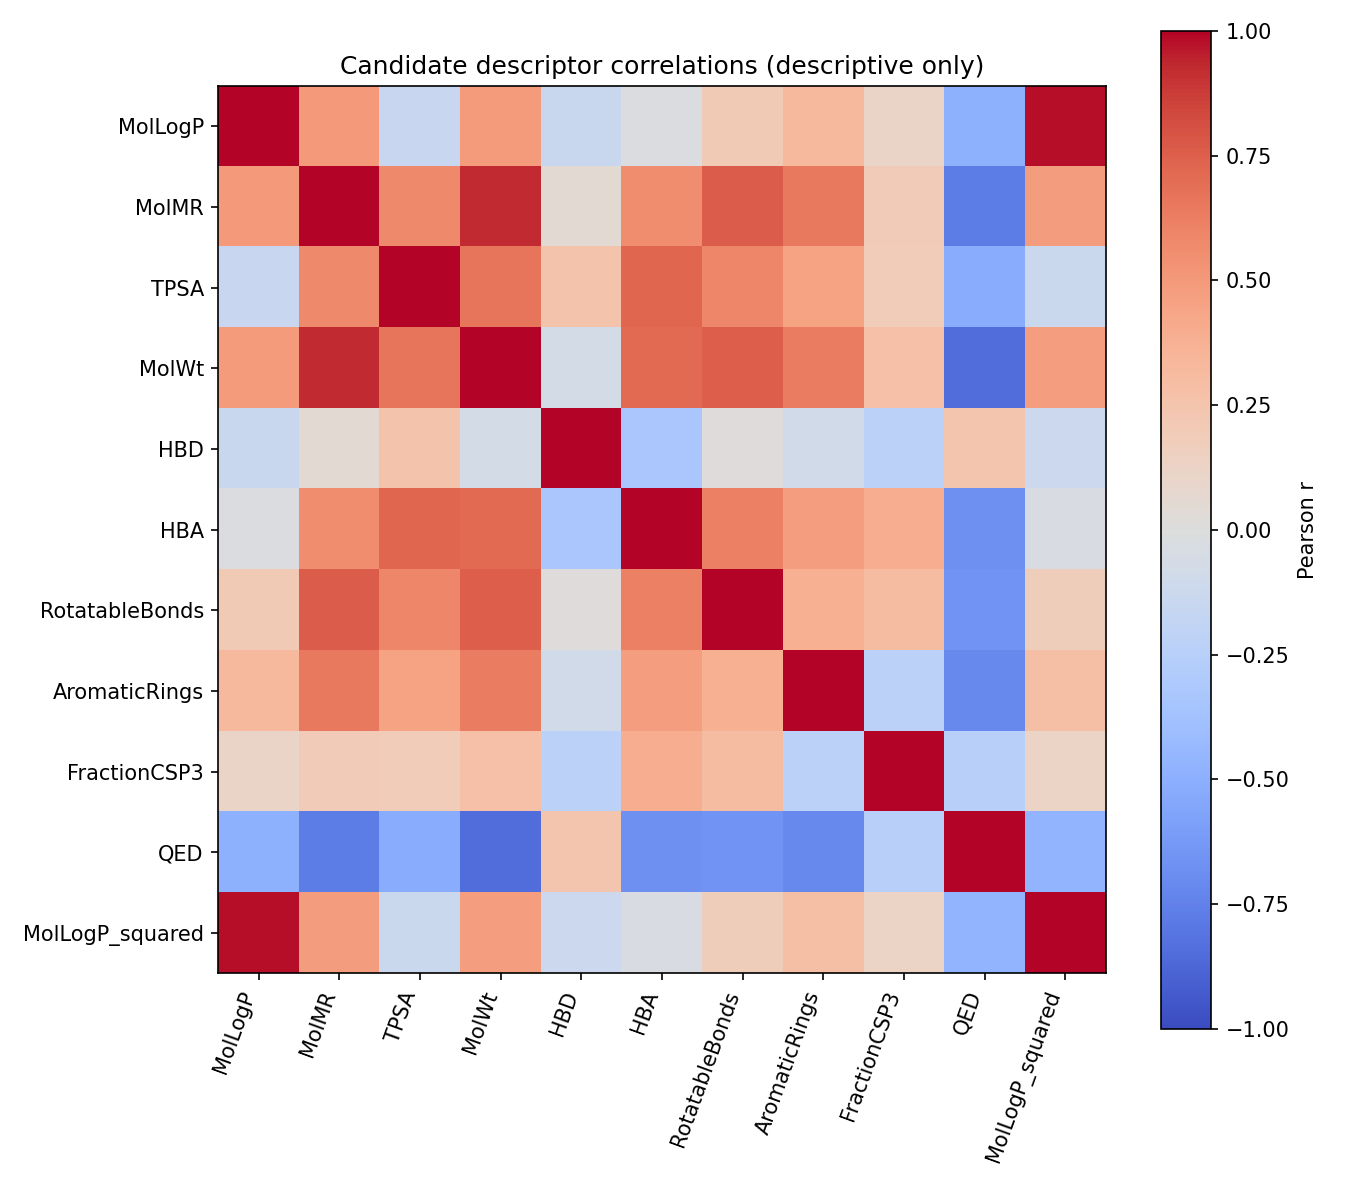

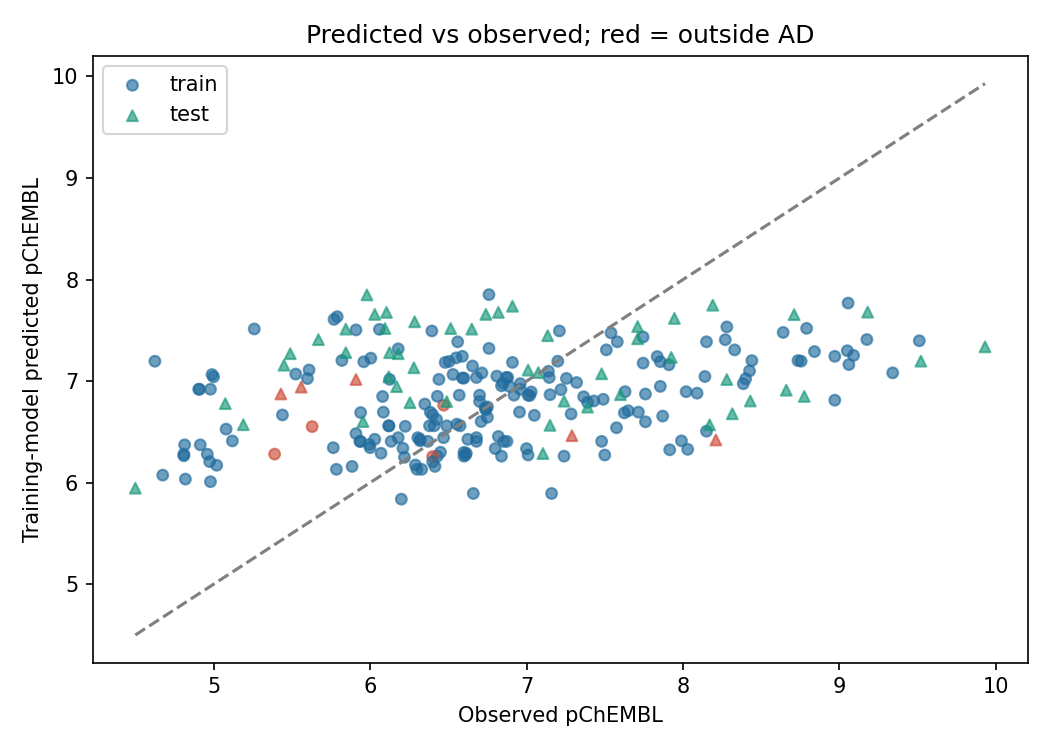

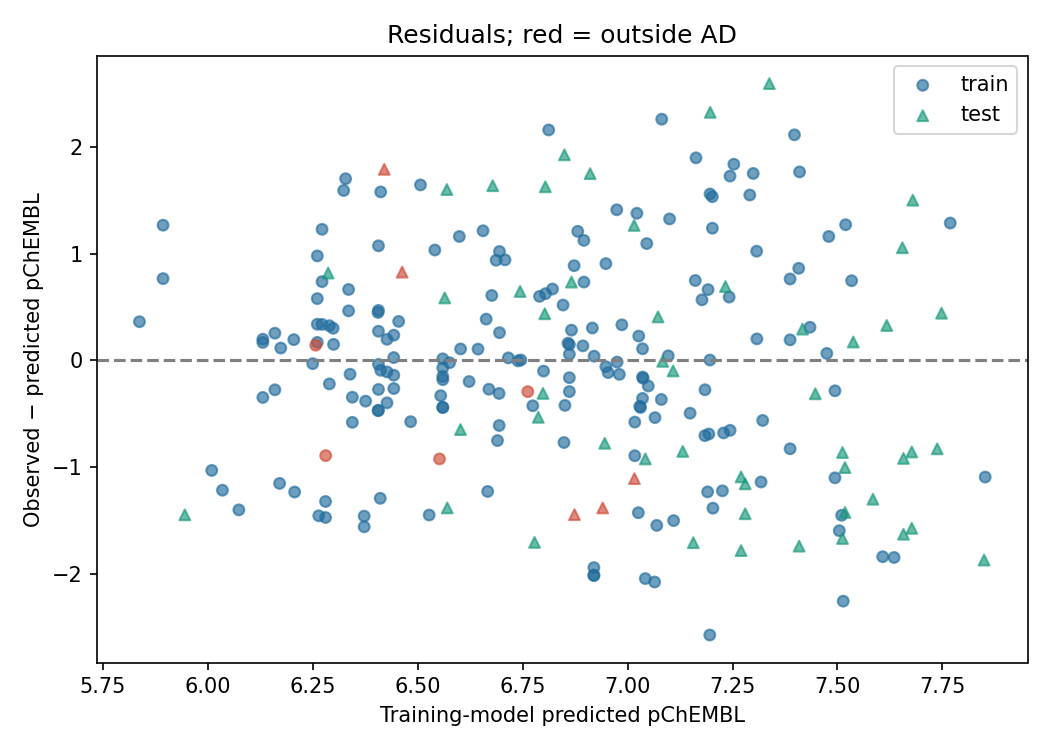

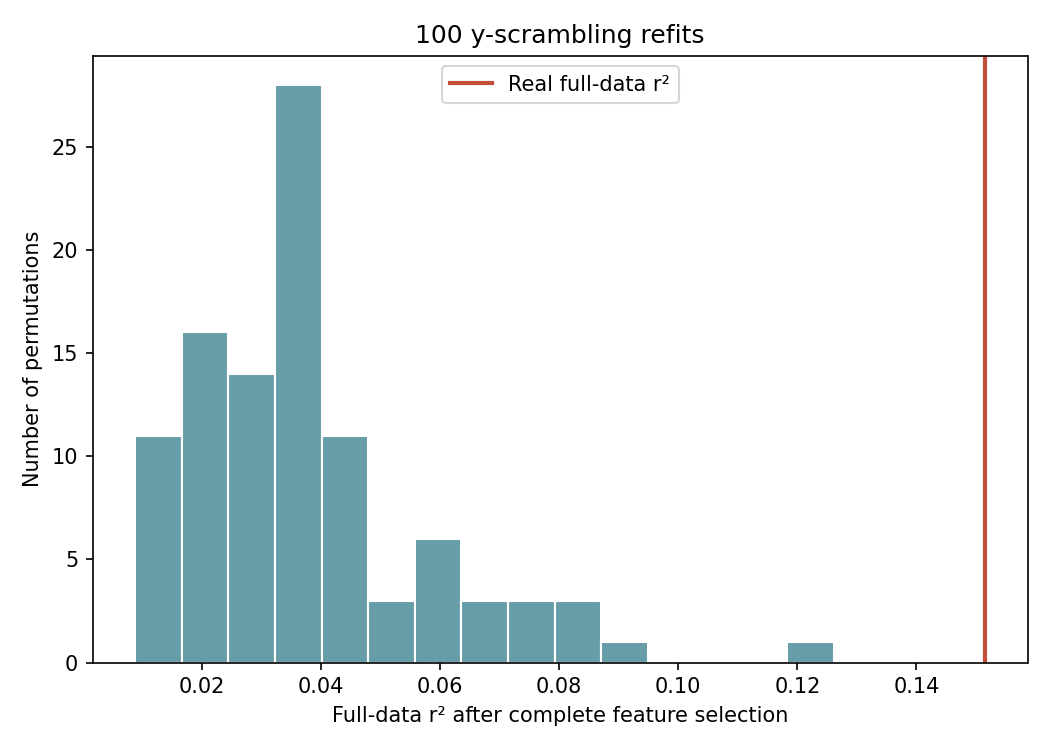

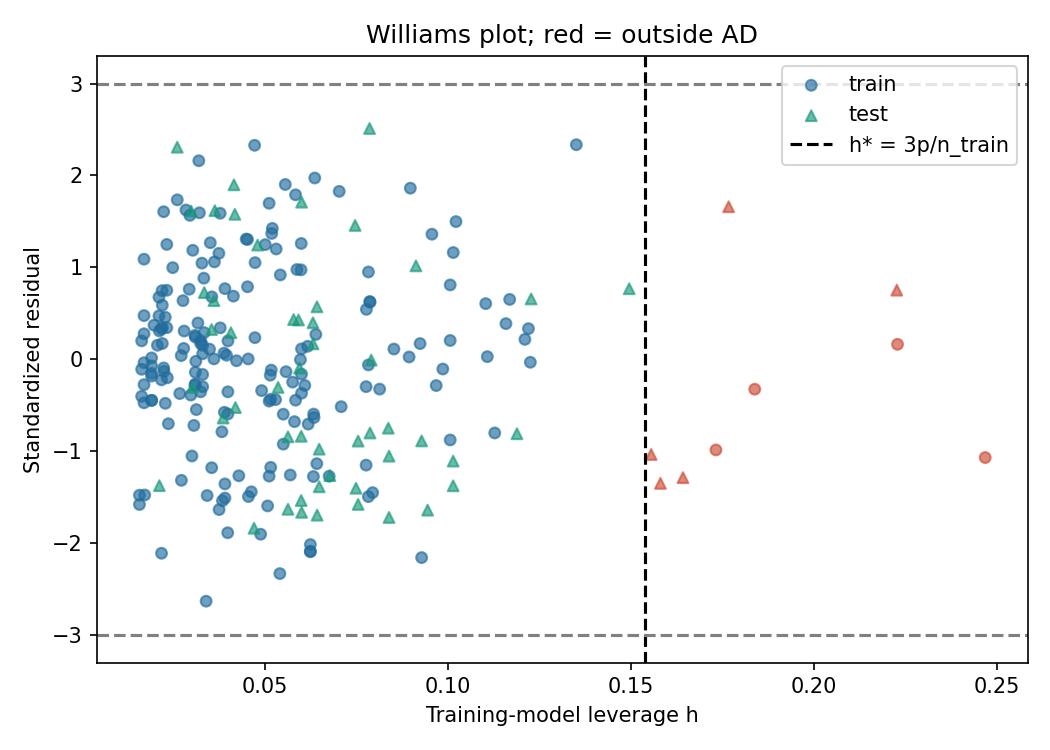

In [7]:
model, dataset, features, analysis = run_pipeline()
for filename in ['correlation_heatmap','predicted_observed','residuals','y_scrambling','williams']:
    display(Image(filename=str(OUT / f'figures/{filename}.png')))
print('Results directory:', OUT.resolve())
print('Site export:', OUT / 'qsar_drd2.json')


## A6 — mandatory cache-only reproduction check

This repeats acquisition, standardization, feature selection, all validation and export.
It cannot access the network. `provenance.csv` continues appending an audit entry for
each cache access, but timestamps are deliberately absent from `model.json`.
An assertion compares the complete output bytes, rather than rounded headline metrics.


In [8]:
before = (OUT/'model.json').read_bytes()
previous_cache_only = CACHE_ONLY
CACHE_ONLY = True
try:
    repeated_model, _, _, _ = run_pipeline(verbose=False)
finally:
    CACHE_ONLY = previous_cache_only
after = (OUT/'model.json').read_bytes()
assert before == after, 'FAIL: cache-only rerun changed model.json'
reproducibility = {'model_sha256':hashlib.sha256(after).hexdigest(),
                   'cache_only_model_bytes_identical':True, 'seed':SEED, 'versions':PINS}
write_json(OUT/'reproducibility.json', reproducibility)
print('PASS: model.json is byte-identical after a complete cache-only rerun.')
print('SHA-256:', reproducibility['model_sha256'])


PASS: model.json is byte-identical after a complete cache-only rerun.
SHA-256: 622ba5d1d93e3ff4eee49b665e0ceeb8645785713ce5660eb8765f2b513aef23


## Assumptions, interpretation and handoff

- **Scope:** one target (human DRD2 / CHEMBL217 / P14416), binding B, Ki only. The retained
  activity records have relation `=`, units nM, finite pChEMBL, assay confidence ≥8,
  null validity comment and duplicate flag 0. Confidence 8 means a homologous single
  protein assignment and confidence 9 a direct single protein assignment. Cross-species
  or unknown assay organisms can coexist with the human target at the requested threshold;
  `selection.json` lists the observed assay organisms rather than silently changing filters.
- **Replication:** compounds are full standardized InChIKeys; distinct ChEMBL document
  IDs operationalize independent publications, not necessarily independent laboratories.
  At least two documents and spread ≤1.0 log
  unit are required. No threshold is silently relaxed. Only finite descriptors and
  MolWt ≤1000 Da are accepted. If fewer than 40 survive, execution stops.
- **Hansch interpretation:** MolLogP is a whole-molecule lipophilicity proxy, not a
  substituent π constant relative to a reference analogue. A target-grouped set is not
  a congeneric series. The fit is exploratory, not a toxicity or clinical-safety model.
- **Validation:** all target-dependent selection is nested inside each training fold
  and each of 100 y-scrambling fits. Feature sets may differ across folds. Five-fold q²
  and LOO q² are pooled `1−PRESS/TSS`; fold r² values are diagnostic. Acyclic molecules
  share one empty-scaffold group. The requested split is 80/20; the frozen snapshot's
  seeded whole-scaffold prefix gives 195 training / 55 test compounds (78/22). No
  scaffold is split to force exact proportions, and the seed/allocation is never tuned
  after inspecting model outcomes. Live-refresh datasets can have different proportions.
- **Verdict rule fixed before inspection:** `predictive` requires both nested q² values
  ≥0.5, scaffold-test r²≥0.3, and real full-data r² above all 100 scrambled fits; `weak`
  requires both q² values and scaffold-test r²>0 and the scrambling pass; otherwise
  `not predictive`. The empirical permutation p is `(1 + count(null r² ≥ real r²))/101`.
- **AD and coefficients:** AD and all primary per-compound predictions use only the
  scaffold training model. Training points are in-sample; test points are held out.
  The separately labelled all-data coefficient table includes SE, p-values and VIF.
  Coefficient p-values are uncorrected exploratory post-selection diagnostics.
- **Reproducibility:** package versions and seed are fixed, rows and ties are sorted,
  numerical threads are set to one, and timestamps/paths are excluded from model JSON.
  The byte-exact guarantee is tested in the same runtime and frozen HTTP cache; different
  CPU/BLAS/Python environments can differ in last-bit floating point results. Cached
  metadata includes response hashes and original retrieval UTC. Preserve the entire
  cache; a future live ChEMBL release is a new dataset, not a rerun of this one. The
  default archive is SHA-256 verified and pinned to an immutable repository commit;
  `QSAR_LIVE_REFRESH=1` deliberately opts into a new snapshot in `live_cache/`.
  `source_provenance.csv` preserves the original acquisition requests, which are also
  imported once into `provenance.csv`; cache reads and new requests append audit rows.
- **Secrets:** no authenticated endpoint is needed. No openFDA request is made and no
  FDA key is requested. If this notebook is later extended to authenticated APIs,
  retrieve credentials only with `google.colab.userdata.get(...)`, never a literal,
  environment fallback, printed value or committed file. The HTTP helper masks key
  query values in provenance. No key is needed to reproduce this analysis.
- **Site handoff:** copy `qsar_drd2.json` into the site's existing root `data/` and
  published `site/data/` directories. The JSON drives a panel on the existing home
  explorer; it contains the conditional fit surface, held-out/in-sample labels,
  observed/predicted values, 100 scrambling r² values, leverage, AD flags and verdict.
  CIDs are supplied only where the pinned existing drug dataset matches the full
  standardized InChIKey. Multiple matching CIDs are preserved as `pubchem_cids`.
- **Audit files:** `raw_activities.csv`, `selection.json`, `dataset.csv`, `dropped.csv`,
  `candidate_features.csv`, `features.csv`, `feature_selection.json`, `predictions.csv`, `outside_domain.csv`,
  `model_table.csv`, `model.json`, `qsar_drd2.json`, `verdict.md`, five figure PNGs,
  `provenance.csv`, `source_provenance.csv`, `reproducibility.json`, and the raw HTTP cache.

Primary API/data references: [ChEMBL web services](https://www.ebi.ac.uk/chembl/api/data/docs),
[DRD2 target record](https://www.ebi.ac.uk/chembl/api/data/target/CHEMBL217.json),
[UniProt P14416](https://www.uniprot.org/uniprotkb/P14416/entry),
[RDKit documentation](https://www.rdkit.org/docs/),
[statsmodels OLS](https://www.statsmodels.org/stable/generated/statsmodels.regression.linear_model.OLS.html).

- **Explorer identity join optimization:** standardize salts, charge and fragments first; skip site structures whose molecular formula cannot match any retained compound before canonicalizing tautomers. Tautomerization preserves formula. Final joins still require the exact full standardized InChIKey. The resulting joins were checked against the unfiltered canonicalization pass.
